# 03 · Granger causality between media coverage and search interest

This notebook reproduces Sections 3.2–4.3 of the paper (Tables 1–2, Figures 4–8, 11–12)
from the daily seasonal windows in `data/processed/daily/`, then adds three checks that
address the limitations listed in Section 5.

| Step | What it does | Paper |
|---|---|---|
| 1 | Load the daily GT and MC series (each normalised to 0–100 within its season) | §2–3.1 |
| 2 | Stationarity tests (ADF, KPSS) | limitation (iii) |
| 3 | Lag selection by AIC on a 20 × 20 grid, asymmetric lags | §3.3, Fig. 4, Fig. 11 |
| 4 | Granger F-test and adjusted R² gain on the full sample | §4.2, Table 2, Fig. 5 |
| 5 | Leave-one-season-out (LOYO) robustness | §4.3, Fig. 6–8 |
| 6 | Estimated coefficients α_k and β_k | Fig. 12 |
| 7 | Sensitivity: comparable AIC values, lags confined to one season | limitations (i), (iv) |

**Model.** For the direction cause → effect:

$$\text{effect}_t = c + \sum_{k=1}^{p_1}\alpha_k\,\text{effect}_{t-k} + \sum_{k=1}^{p_2}\beta_k\,\text{cause}_{t-k} + \varepsilon_t,
\qquad H_0:\ \beta_1=\dots=\beta_{p_2}=0 .$$

The test compares this full model with the reduced model without the cause:
$F = \dfrac{(RSS_{red}-RSS_{full})/p_2}{RSS_{full}/(n-p_1-p_2-1)}$.
The effect size is the gain in adjusted R², with $k=p_1$ (reduced) and $k=p_1+p_2$ (full).

All estimation code lives in `src/phc/granger.py`; this notebook only calls it and plots.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "phc").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from phc.config import CAMPAIGNS, FIG_DIR, TAB_DIR
from phc import granger as G

MAX_LAG = 20
ALPHA = 0.05
CODES = ["DJ", "MB", "Mov", "OR"]          # order of Table 2
LABEL = {c: CAMPAIGNS[c].label for c in CODES}
DIR_COLOR = {"GT → MC": "#2a6fb0", "MC → GT": "#c8553d"}

pd.set_option("display.float_format", lambda v: f"{v:.4g}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

## 1. Data

One row per day inside the yearly campaign window (11 seasons per campaign).
Seasons are concatenated in time order.

In [2]:
data = {c: G.load_daily(c) for c in CODES}
pd.DataFrame({
    LABEL[c]: {"days": len(df), "seasons": df["season"].nunique(),
               "first day": df.index.min().date(), "last day": df.index.max().date(),
               "days per season": int(df.groupby("season").size().median())}
    for c, df in data.items()
}).T

,days,seasons,first day,last day,days per season
Dry January,473,11,2015-12-26,2026-02-06,43
Mars Bleu,971,11,2015-02-02,2025-04-30,88
Movember,1012,11,2015-10-01,2025-12-31,92
Octobre Rose,1001,11,2015-09-01,2025-11-30,91


## 2. Stationarity

The Granger F-test assumes stationary series. ADF tests the null of a unit root;
KPSS tests the null of stationarity (its p-value is bounded to [0.01, 0.10] by the
look-up table, so 0.01 means "< 0.01" and 0.10 means "> 0.10").

In [3]:
stat = pd.concat({LABEL[c]: G.stationarity(df).set_index("series") for c, df in data.items()})
stat.to_csv(TAB_DIR / "stationarity_tests.csv")
stat[["adf_pval", "kpss_pval"]]

adf_pval  kpss_pval
             series                     
Dry January  gt     1.079e-08       0.01
             mc     3.955e-09       0.01
Mars Bleu    gt     8.362e-05        0.1
             mc     4.003e-09    0.01619
Movember     gt     3.116e-08        0.1
             mc     1.827e-13        0.1
Octobre Rose gt     5.146e-06       0.01
             mc     1.128e-07        0.1

ADF rejects a unit root for every series (p < 0.001). KPSS nevertheless rejects
stationarity at the 1% level for Dry January (GT and MC) and Octobre Rose (GT), and at
5% for Mars Bleu (MC). The two tests together suggest no unit root but some
non-constant mean, which is expected: each season is a pulse around the campaign,
and Dry January search interest is near zero before 2019. Results below should be
read with that in mind.

## 3. Lag selection by AIC (paper specification)

For each campaign and direction, $(p_1, p_2)$ minimises the AIC of the full model over
$1 \le p_1, p_2 \le 20$. As in the original code, each cell is estimated on its own
sample (starting at day $\max(p_1,p_2)$) and lags run across season boundaries.

In [4]:
lags, grids = {}, {}
for c, df in data.items():
    for effect, cause, lab in G.DIRECTIONS:
        grid = G.aic_grid(df, effect, cause, MAX_LAG)
        grids[c, lab] = grid
        lags[c, lab] = G.best_lags(grid)
pd.Series({f"{LABEL[c]} {lab}": v for (c, lab), v in lags.items()}, name="(p1*, p2*)").to_frame()

,"(p1*, p2*)"
Dry January GT → MC,"(7, 20)"
Dry January MC → GT,"(20, 1)"
Mars Bleu GT → MC,"(7, 20)"
Mars Bleu MC → GT,"(20, 1)"
Movember GT → MC,"(7, 20)"
Movember MC → GT,"(20, 2)"
Octobre Rose GT → MC,"(13, 20)"
Octobre Rose MC → GT,"(20, 7)"


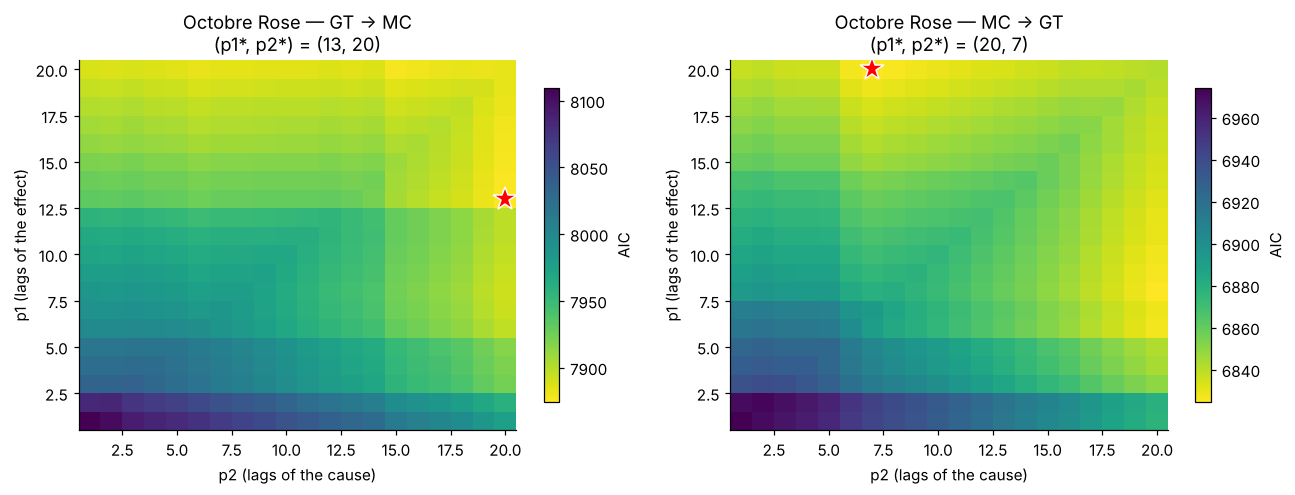

In [5]:
def plot_aic(ax, grid, p_opt, title):
    im = ax.imshow(grid.values, origin="lower", aspect="auto", cmap="viridis_r",
                   extent=[0.5, grid.shape[1] + 0.5, 0.5, grid.shape[0] + 0.5])
    ax.plot(p_opt[1], p_opt[0], marker="*", color="red", ms=16, mec="white")
    ax.set(title=f"{title}\n(p1*, p2*) = {p_opt}", xlabel="p2 (lags of the cause)",
           ylabel="p1 (lags of the effect)")
    ax.grid(False)
    plt.colorbar(im, ax=ax, label="AIC", shrink=0.85)


# Figure 4: Octobre Rose
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (_, _, lab) in zip(axes, G.DIRECTIONS):
    plot_aic(ax, grids["OR", lab], lags["OR", lab], f"Octobre Rose — {lab}")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig04_aic_octobre_rose.png", dpi=200, bbox_inches="tight")

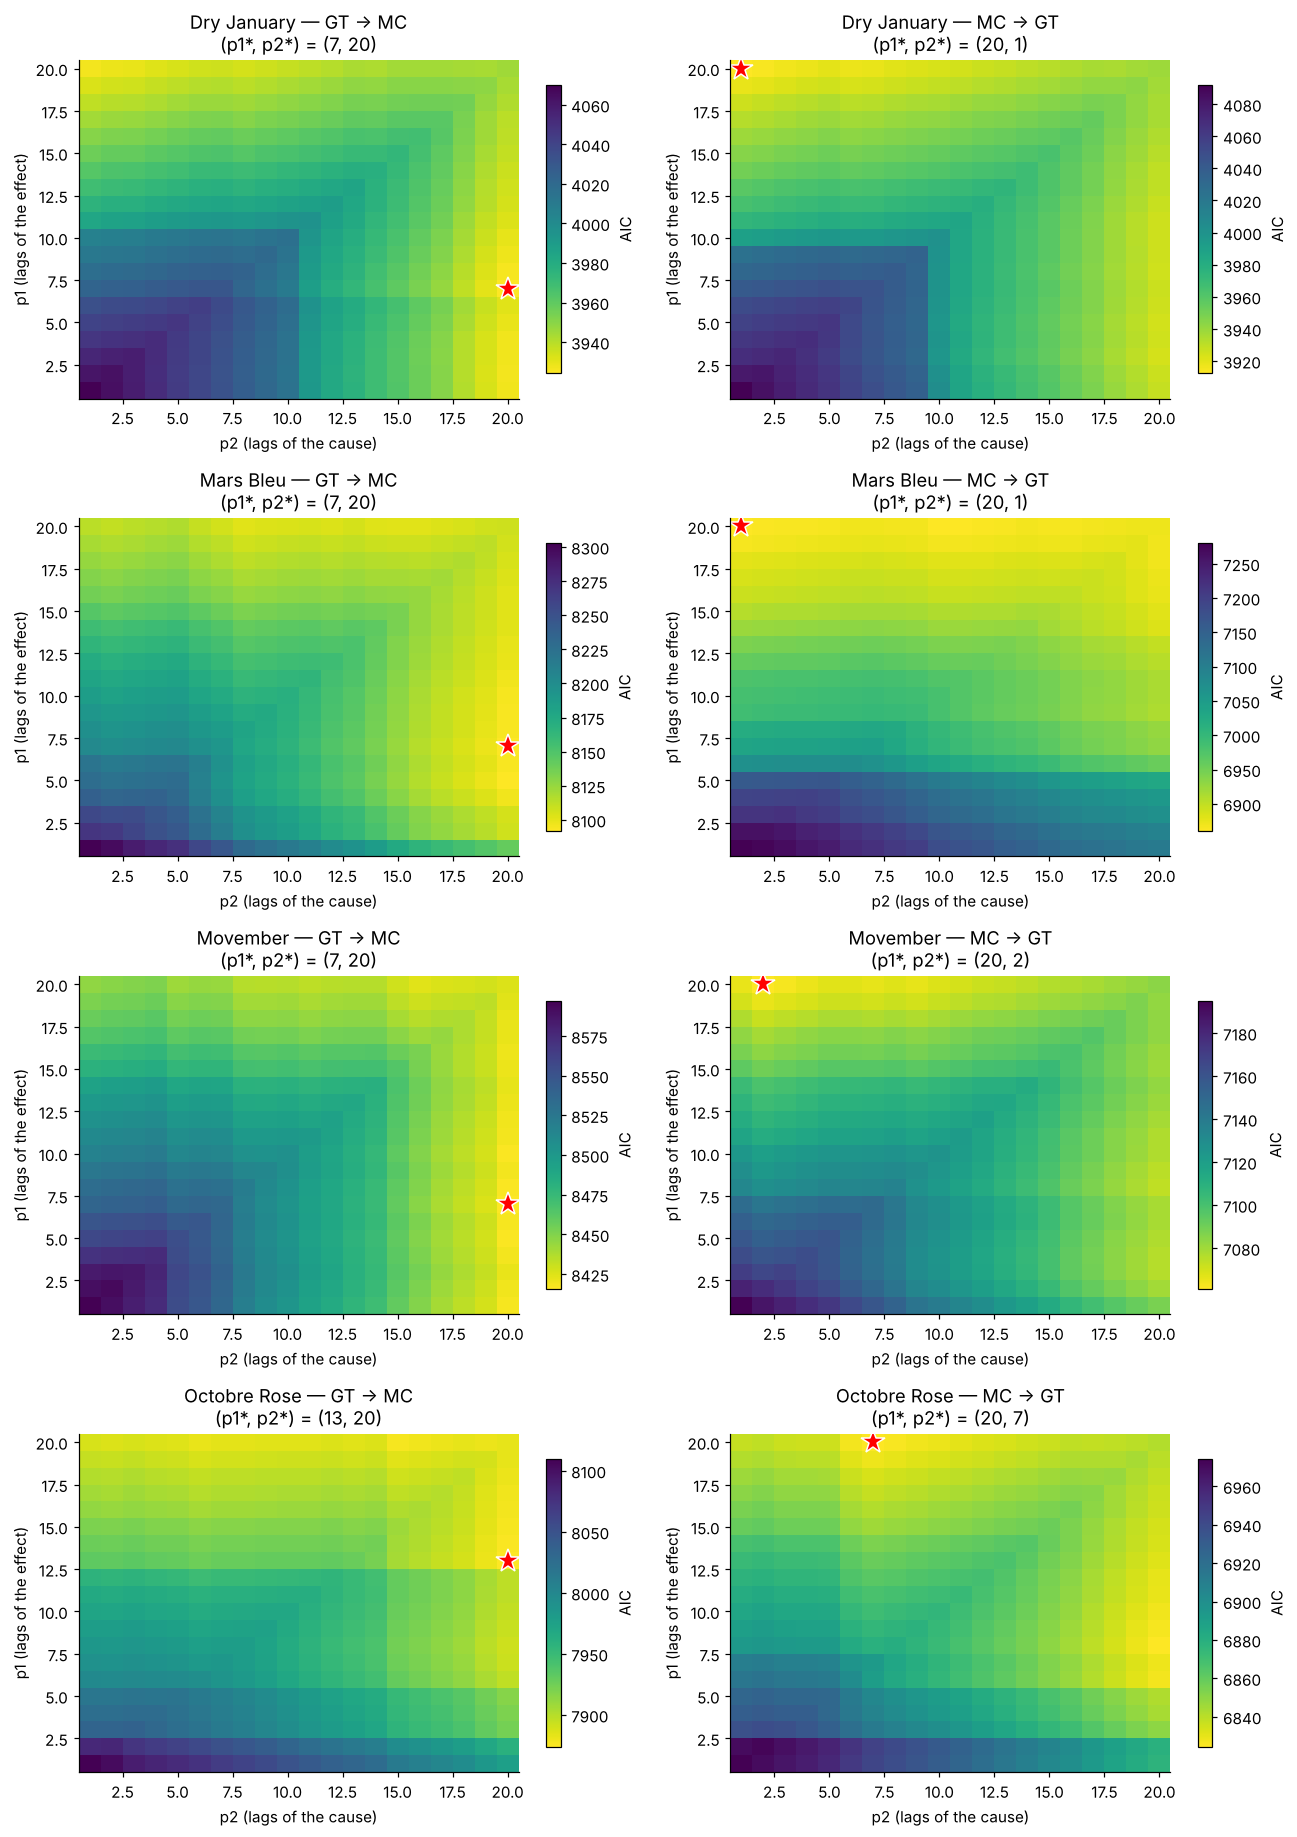

In [6]:
# Figure 11: all campaigns
fig, axes = plt.subplots(len(CODES), 2, figsize=(12, 4.2 * len(CODES)))
for i, c in enumerate(CODES):
    for j, (_, _, lab) in enumerate(G.DIRECTIONS):
        plot_aic(axes[i, j], grids[c, lab], lags[c, lab], f"{LABEL[c]} — {lab}")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig11_aic_all_campaigns.png", dpi=200, bbox_inches="tight")

In all 8 models one of the two lag orders hits the upper bound of the grid
($p_2^*=20$ for GT → MC, $p_1^*=20$ for MC → GT). Section 7 shows that this is largely
an artefact of comparing AIC values computed on different samples.

## 4. Granger test on the full sample (Table 2)

In [7]:
rows = []
for c, df in data.items():
    for effect, cause, lab in G.DIRECTIONS:
        p1, p2 = lags[c, lab]
        res = G.granger_test(df, effect, cause, p1, p2)
        lo = G.loyo(df, effect, cause, p1, p2, alpha=ALPHA)
        rows.append({"campaign": LABEL[c], "direction": lab, "(p1*, p2*)": (p1, p2),
                     **{k: res[k] for k in ("n", "F", "pval", "r2adj_red", "r2adj_full", "delta_r2adj")},
                     "LOYO significant": f"{lo['significant'].sum()}/{len(lo)}",
                     "LOYO mean ΔR²adj": lo["delta_r2adj"].mean()})
table2 = pd.DataFrame(rows)
table2.to_csv(TAB_DIR / "table2_granger_full_sample.csv", index=False)
table2

,campaign,direction,"(p1*, p2*)",n,F,pval,r2adj_red,r2adj_full,delta_r2adj,LOYO significant,LOYO mean ΔR²adj
0,Dry January,GT → MC,"(7, 20)",453,2.359,0.0008946,0.2618,0.3043,0.04248,11/11,0.04385
1,Dry January,MC → GT,"(20, 1)",453,14.63,0.0001498,0.461,0.4775,0.01649,10/11,0.01703
2,Mars Bleu,GT → MC,"(7, 20)",951,2.868,2.726e-05,0.2375,0.2665,0.02906,11/11,0.02909
3,Mars Bleu,MC → GT,"(20, 1)",951,4.935,0.02655,0.7444,0.7455,0.001077,10/11,0.001085
4,Movember,GT → MC,"(7, 20)",992,3.824,3.6e-08,0.1043,0.1529,0.04862,11/11,0.04947
5,Movember,MC → GT,"(20, 2)",992,6.165,0.002186,0.7222,0.7252,0.002924,11/11,0.002897
6,Octobre Rose,GT → MC,"(13, 20)",981,4.731,4.872e-11,0.5449,0.5775,0.03261,11/11,0.03325
7,Octobre Rose,MC → GT,"(20, 7)",981,3.627,0.0007214,0.8201,0.8235,0.003382,11/11,0.003453


### Check against the paper

The values printed in Table 2 of the paper are compared below with the values
recomputed here.

In [8]:
paper = pd.DataFrame([
    ("Dry January", "GT → MC", (7, 20), 0.262, 0.304, 0.042, 9.0e-4, "11/11"),
    ("Dry January", "MC → GT", (20, 1), 0.461, 0.477, 0.016, 1.5e-4, "10/11"),
    ("Mars Bleu", "GT → MC", (7, 20), 0.237, 0.267, 0.030, 2.7e-5, "11/11"),
    ("Mars Bleu", "MC → GT", (20, 1), 0.744, 0.745, 0.001, 2.6e-2, "10/11"),
    ("Movember", "GT → MC", (7, 20), 0.104, 0.153, 0.049, 1.0e-4, "11/11"),
    ("Movember", "MC → GT", (20, 2), 0.722, 0.725, 0.003, 2.0e-3, "11/11"),
    ("Octobre Rose", "GT → MC", (13, 20), 0.545, 0.577, 0.032, 3.0e-4, "11/11"),
    ("Octobre Rose", "MC → GT", (20, 7), 0.820, 0.823, 0.003, 7.0e-4, "11/11"),
], columns=["campaign", "direction", "(p1*, p2*)", "r2adj_red", "r2adj_full",
            "delta_r2adj", "pval", "LOYO significant"])

cmp = table2.merge(paper, on=["campaign", "direction"], suffixes=("", "_paper"))
check = pd.DataFrame({
    "campaign": cmp["campaign"], "direction": cmp["direction"],
    "lags match": cmp["(p1*, p2*)"] == cmp["(p1*, p2*)_paper"],
    "R² match (3 d.p.)": [all(abs(cmp.loc[i, k] - cmp.loc[i, k + "_paper"]) < 0.0015
                              for k in ("r2adj_red", "r2adj_full")) for i in cmp.index],
    "LOYO match": cmp["LOYO significant"] == cmp["LOYO significant_paper"],
    "p-value (recomputed)": cmp["pval"], "p-value (paper)": cmp["pval_paper"],
})
check

,campaign,direction,lags match,R² match (3 d.p.),LOYO match,p-value (recomputed),p-value (paper)
0,Dry January,GT → MC,True,True,True,0.0008946,0.0009
1,Dry January,MC → GT,True,True,True,0.0001498,0.00015
2,Mars Bleu,GT → MC,True,True,True,2.726e-05,2.7e-05
3,Mars Bleu,MC → GT,True,True,True,0.02655,0.026
4,Movember,GT → MC,True,True,True,3.6e-08,0.0001
5,Movember,MC → GT,True,True,True,0.002186,0.002
6,Octobre Rose,GT → MC,True,True,True,4.872e-11,0.0003
7,Octobre Rose,MC → GT,True,True,True,0.0007214,0.0007


Lags, adjusted R² values and LOYO counts all match the paper. Two p-values do not:
for **Movember GT → MC** and **Octobre Rose GT → MC** the recomputed p-values
(about $4\times10^{-8}$ and $5\times10^{-11}$) are several orders of magnitude smaller
than the printed ones ($1.0\times10^{-4}$ and $3.0\times10^{-4}$). The same design
matrix fitted with `statsmodels` gives the same F and p as here, so the printed values
should be corrected. This does not change any conclusion: both tests were already
significant.

A ΔR²adj difference of 0.001 (Mars Bleu GT → MC, Octobre Rose GT → MC) comes from
rounding: the paper subtracts the rounded R² values.

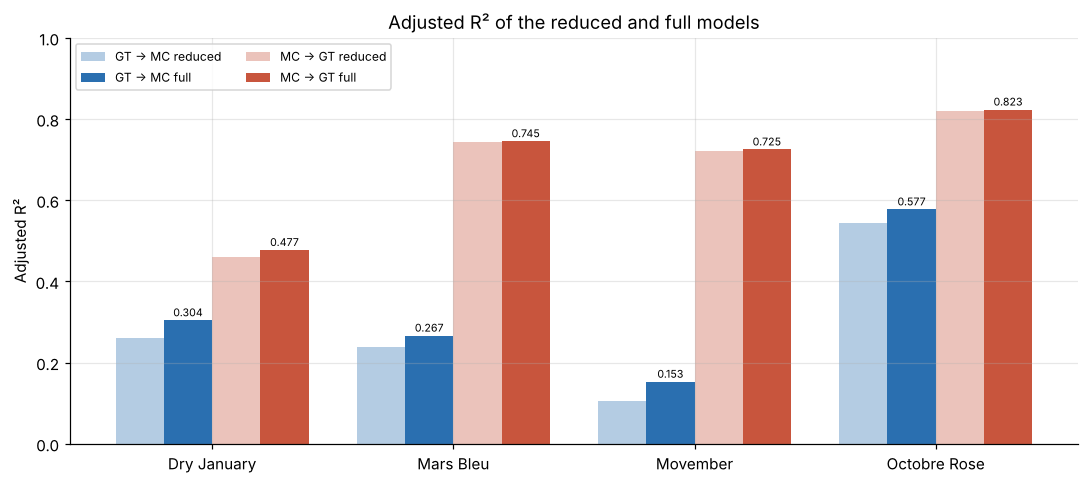

In [9]:
# Figure 5: adjusted R² of reduced and full models
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(CODES))
w = 0.2
for j, (_, _, lab) in enumerate(G.DIRECTIONS):
    sub = table2[table2["direction"] == lab].set_index("campaign").loc[[LABEL[c] for c in CODES]]
    col = DIR_COLOR[lab]
    off = (-1.5 + 2 * j) * w
    ax.bar(x + off, sub["r2adj_red"], w, color=col, alpha=0.35, label=f"{lab} reduced")
    ax.bar(x + off + w, sub["r2adj_full"], w, color=col, label=f"{lab} full")
    for xi, v in zip(x + off + w, sub["r2adj_full"]):
        ax.text(xi, v + 0.01, f"{v:.3f}", ha="center", fontsize=7)
ax.set(xticks=x, xticklabels=[LABEL[c] for c in CODES], ylabel="Adjusted R²", ylim=(0, 1))
ax.legend(ncol=2, fontsize=8, loc="upper left")
ax.set_title("Adjusted R² of the reduced and full models")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig05_adjusted_r2.png", dpi=200, bbox_inches="tight")

Both directions are significant at 5% for every campaign, but the gains are small:
0.03–0.05 for GT → MC and at most 0.016 for MC → GT, because past GT values already
explain 46–82% of GT's variance.

## 5. Leave-one-season-out robustness (Figures 6–8)

Each season is removed in turn and the test is re-estimated with the full-sample lags.

In [10]:
loyo = {}
for c, df in data.items():
    for effect, cause, lab in G.DIRECTIONS:
        loyo[c, lab] = G.loyo(df, effect, cause, *lags[c, lab], alpha=ALPHA)
loyo_all = pd.concat({(LABEL[c], lab): d for (c, lab), d in loyo.items()},
                     names=["campaign", "direction"]).reset_index(level=[0, 1])
loyo_all.to_csv(TAB_DIR / "loyo_folds.csv", index=False)

# Folds that are not significant
loyo_all.loc[~loyo_all["significant"], ["campaign", "direction", "held_out", "pval", "delta_r2adj"]]

,campaign,direction,held_out,pval,delta_r2adj
2,Dry January,MC → GT,2017-2018,0.07334,0.002871
6,Mars Bleu,MC → GT,2021,0.3516,-4.375e-05


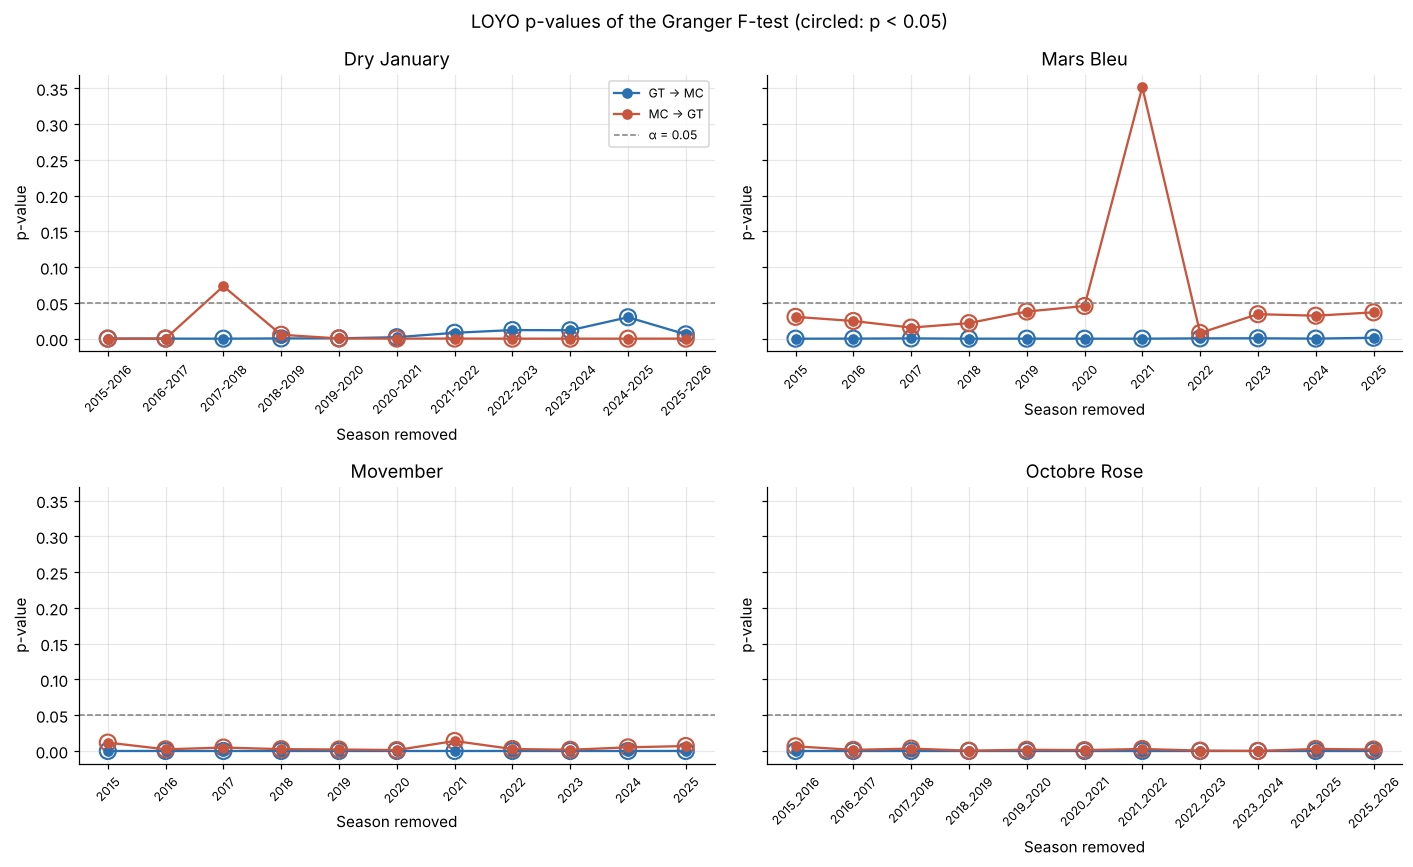

In [11]:
# Figure 6: LOYO p-values
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for ax, c in zip(axes.flat, CODES):
    for _, _, lab in G.DIRECTIONS:
        d = loyo[c, lab]
        ax.plot(d["held_out"], d["pval"], marker="o", color=DIR_COLOR[lab], label=lab)
        sig = d["significant"]
        ax.scatter(d.loc[sig, "held_out"], d.loc[sig, "pval"], s=110, facecolors="none",
                   edgecolors=DIR_COLOR[lab], linewidths=1.4)
    ax.axhline(ALPHA, color="grey", ls="--", lw=1, label="α = 0.05")
    ax.set(title=LABEL[c], ylabel="p-value", xlabel="Season removed")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
axes[0, 0].legend(fontsize=8)
fig.suptitle("LOYO p-values of the Granger F-test (circled: p < 0.05)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig06_loyo_pvalues.png", dpi=200, bbox_inches="tight")

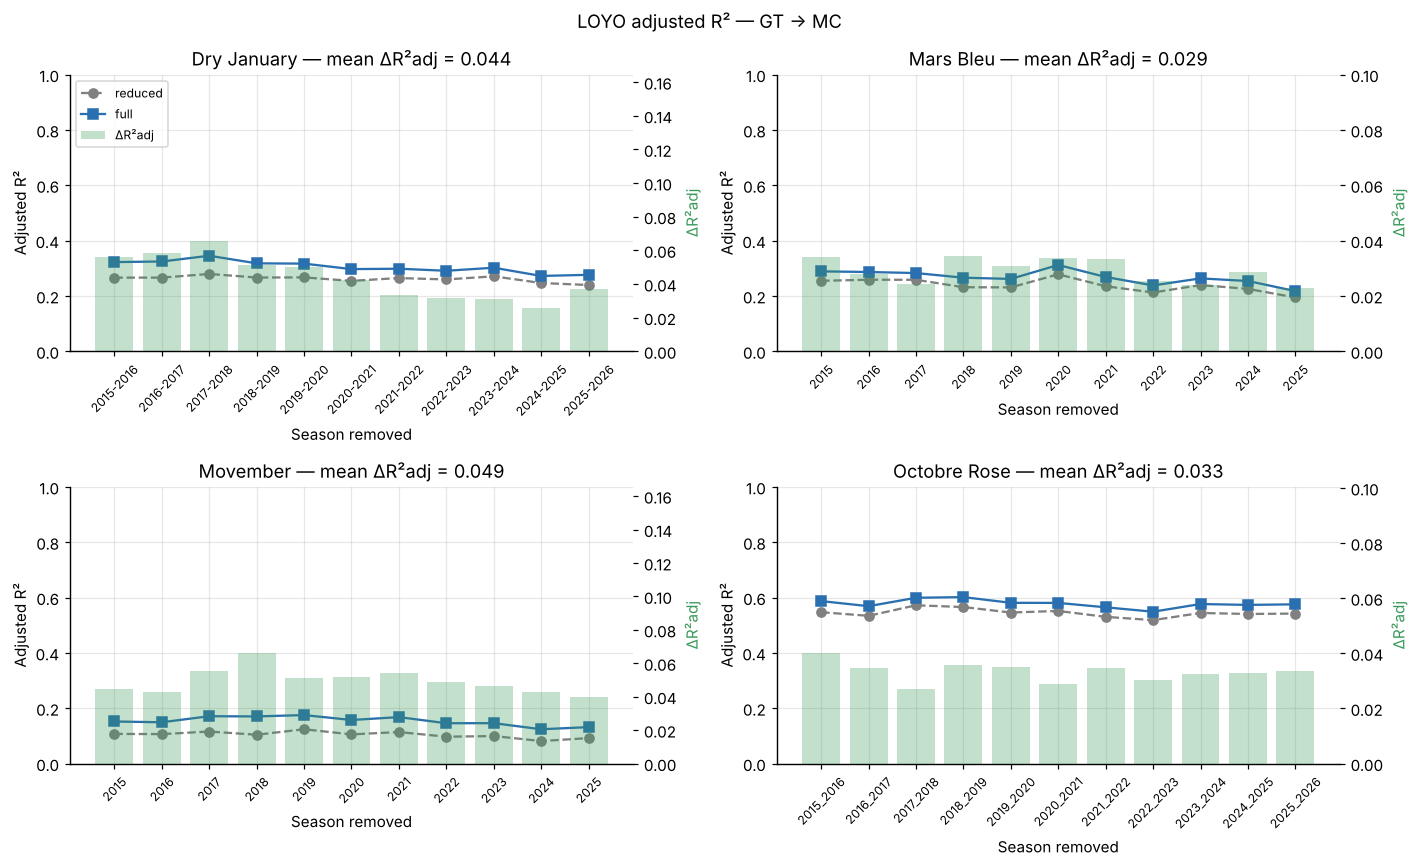

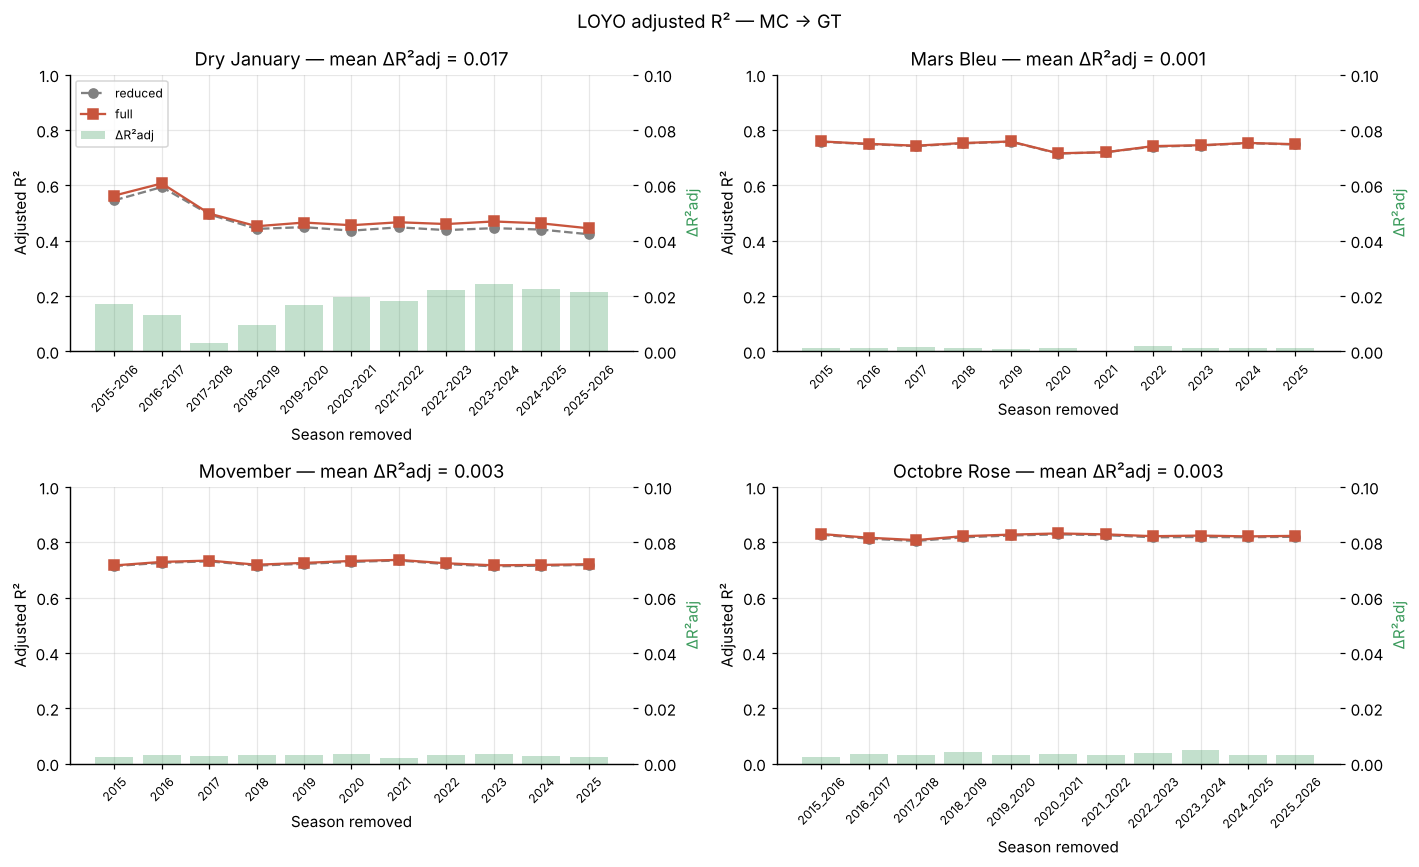

In [12]:
# Figures 7–8: LOYO adjusted R²
def plot_loyo_r2(lab, fname):
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    for ax, c in zip(axes.flat, CODES):
        d = loyo[c, lab]
        ax.plot(d["held_out"], d["r2adj_red"], marker="o", ls="--", color="grey", label="reduced")
        ax.plot(d["held_out"], d["r2adj_full"], marker="s", color=DIR_COLOR[lab], label="full")
        ax.set(ylim=(0, 1), ylabel="Adjusted R²", xlabel="Season removed",
               title=f"{LABEL[c]} — mean ΔR²adj = {d['delta_r2adj'].mean():.3f}")
        ax.tick_params(axis="x", rotation=45, labelsize=8)
        ax2 = ax.twinx()
        ax2.bar(d["held_out"], d["delta_r2adj"], color="#3a9a5b", alpha=0.3, label="ΔR²adj")
        ax2.set_ylabel("ΔR²adj", color="#3a9a5b")
        ax2.set_ylim(0, max(0.1, d["delta_r2adj"].max() * 2.5))
        ax2.grid(False)
        if c == CODES[0]:
            h1, l1 = ax.get_legend_handles_labels()
            h2, l2 = ax2.get_legend_handles_labels()
            ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
    fig.suptitle(f"LOYO adjusted R² — {lab}")
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=200, bbox_inches="tight")


plot_loyo_r2("GT → MC", "fig07_loyo_r2_gt_to_mc.png")
plot_loyo_r2("MC → GT", "fig08_loyo_r2_mc_to_gt.png")

GT → MC stays significant in every fold. MC → GT is more fragile: removing the 2021
season makes Mars Bleu non-significant, and removing 2017–2018 does the same for
Dry January (see the table of non-significant folds above).

## 6. Estimated coefficients (Figure 12)

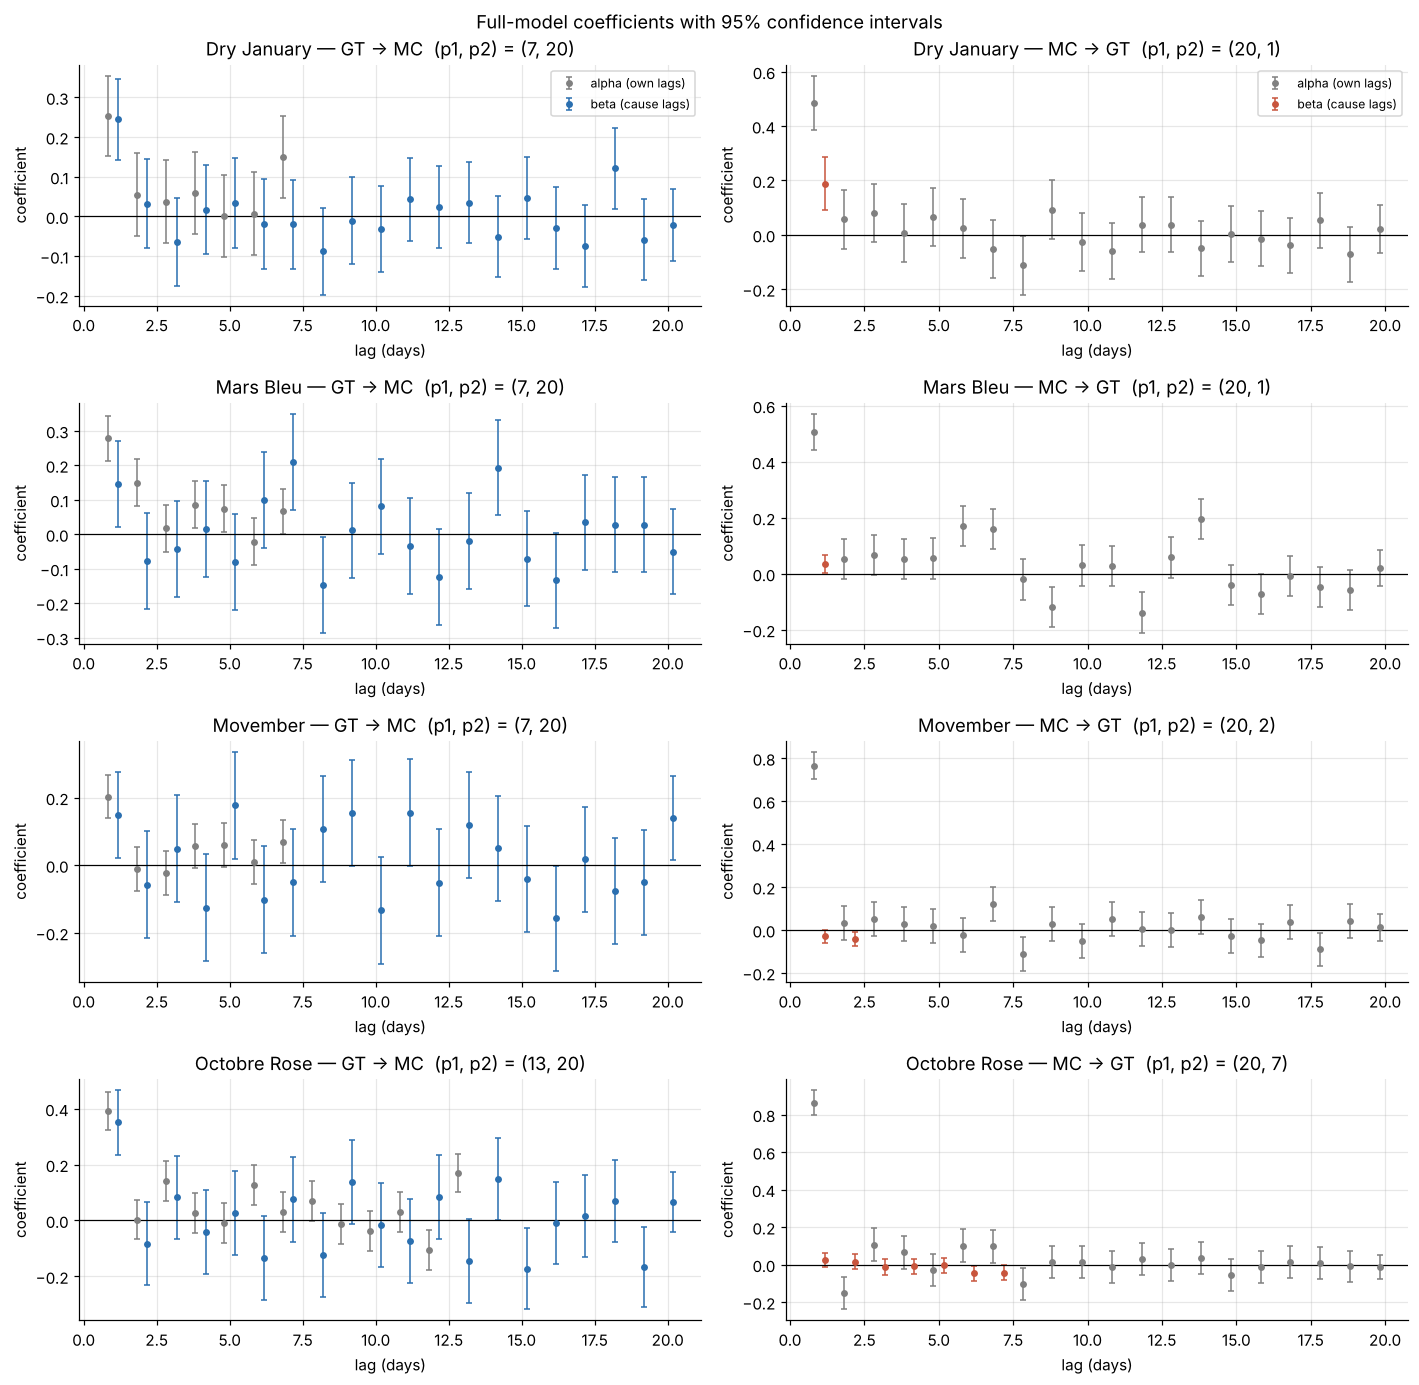

In [13]:
fig, axes = plt.subplots(len(CODES), 2, figsize=(13, 3.2 * len(CODES)))
for i, c in enumerate(CODES):
    for j, (effect, cause, lab) in enumerate(G.DIRECTIONS):
        ax = axes[i, j]
        co = G.coefficients(data[c], effect, cause, *lags[c, lab])
        for kind, col, shift in (("alpha", "grey", -0.18), ("beta", DIR_COLOR[lab], 0.18)):
            k = co[co["kind"] == kind]
            ax.errorbar(k["lag"] + shift, k["coef"],
                        yerr=[k["coef"] - k["ci_low"], k["ci_high"] - k["coef"]],
                        fmt="o", ms=3.5, color=col, capsize=2, lw=1,
                        label=f"{kind} ({'own lags' if kind == 'alpha' else 'cause lags'})")
        ax.axhline(0, color="black", lw=0.8)
        ax.set(title=f"{LABEL[c]} — {lab}  (p1, p2) = {lags[c, lab]}", xlabel="lag (days)",
               ylabel="coefficient")
        if i == 0:
            ax.legend(fontsize=8)
fig.suptitle("Full-model coefficients with 95% confidence intervals")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig12_coefficients.png", dpi=200, bbox_inches="tight")

## 7. Sensitivity analyses

The paper lists two limitations that can be tested directly:

* **(iv) Lags at the grid bound.** The original AIC grid fits each $(p_1,p_2)$ on a
  different number of days (the sample starts at $\max(p_1,p_2)$), so AIC values are not
  strictly comparable. Here every cell is estimated on the same days (from day 20).
* **(i) Lags crossing seasons.** Because seasons are concatenated, the first days of a
  season are partly "explained" by the last days of the previous one. Here lags are
  computed within each season only (and the first 20 days of each season are dropped
  in the lag search, which shortens the sample, notably for the 43-day Dry January window).

In [14]:
variants = {
    "paper": dict(common_sample=False, by_season=False),
    "comparable AIC": dict(common_sample=True, by_season=False),
    "comparable AIC + within-season lags": dict(common_sample=True, by_season=True),
}
rows = []
for c, df in data.items():
    for effect, cause, lab in G.DIRECTIONS:
        for name, opt in variants.items():
            grid = G.aic_grid(df, effect, cause, MAX_LAG, **opt)
            p1, p2 = G.best_lags(grid)
            res = G.granger_test(df, effect, cause, p1, p2, by_season=opt["by_season"])
            lo = G.loyo(df, effect, cause, p1, p2, by_season=opt["by_season"], alpha=ALPHA)
            rows.append({"campaign": LABEL[c], "direction": lab, "variant": name,
                         "(p1*, p2*)": (p1, p2), "n": res["n"], "pval": res["pval"],
                         "delta_r2adj": res["delta_r2adj"],
                         "LOYO significant": f"{lo['significant'].sum()}/{len(lo)}"})
sens = pd.DataFrame(rows)
sens.to_csv(TAB_DIR / "sensitivity_granger.csv", index=False)

# One cell per variant: lags · p-value · LOYO
sens["summary"] = sens.apply(lambda r: f"{r['(p1*, p2*)']} · p={r['pval']:.1e} · LOYO {r['LOYO significant']}", axis=1)
sens.pivot(index=["campaign", "direction"], columns="variant", values="summary")[list(variants)]

variant                                             paper  \
campaign     direction                                      
Dry January  GT → MC     (7, 20) · p=8.9e-04 · LOYO 11/11   
             MC → GT     (20, 1) · p=1.5e-04 · LOYO 10/11   
Mars Bleu    GT → MC     (7, 20) · p=2.7e-05 · LOYO 11/11   
             MC → GT     (20, 1) · p=2.7e-02 · LOYO 10/11   
Movember     GT → MC     (7, 20) · p=3.6e-08 · LOYO 11/11   
             MC → GT     (20, 2) · p=2.2e-03 · LOYO 11/11   
Octobre Rose GT → MC    (13, 20) · p=4.9e-11 · LOYO 11/11   
             MC → GT     (20, 7) · p=7.2e-04 · LOYO 11/11   

variant                                    comparable AIC  \
campaign     direction                                      
Dry January  GT → MC      (7, 1) · p=4.4e-11 · LOYO 11/11   
             MC → GT      (3, 1) · p=4.0e-04 · LOYO 11/11   
Mars Bleu    GT → MC     (7, 16) · p=3.7e-06 · LOYO 11/11   
             MC → GT     (19, 1) · p=2.7e-02 · LOYO 10/11   
Movember     GT → MC     (7, 16) · p=1.7e-08 · LOYO 11/11   
             MC → GT      (8, 2) · p=2.6e-03 · LOYO 11/11   
Octobre Rose GT → MC    (13, 15) · p=6.4e-12 · LOYO 11/11   
             MC → GT      (8, 7) · p=4.0e-04 · LOYO 11/11   

variant                comparable AIC + within-season lags  
campaign     direction                                      
Dry January  GT → MC       (18, 1) · p=2.7e-01 · LOYO 0/11  
             MC → GT       (9, 1) · p=2.6e-05 · LOYO 10/11  
Mars Bleu    GT → MC     (10, 16) · p=1.2e-08 · LOYO 11/11  
             MC → GT       (17, 1) · p=4.2e-01 · LOYO 0/11  
Movember     GT → MC      (1, 16) · p=3.7e-11 · LOYO 11/11  
             MC → GT       (8, 2) · p=5.0e-03 · LOYO 11/11  
Octobre Rose GT → MC     (13, 15) · p=8.5e-10 · LOYO 11/11  
             MC → GT       (8, 7) · p=7.4e-04 · LOYO 11/11

**Reading the sensitivity table.**

* With comparable AIC values, no selected lag order is at the bound of 20 any more
  (for example Dry January MC → GT goes from (20, 1) to (3, 1)). All eight tests stay
  significant, with the same LOYO counts or better.
* When lags are also kept within a season, two results are no longer significant:
  **Dry January GT → MC** and **Mars Bleu MC → GT**. Part of their significance in the
  paper specification therefore comes from lags that link one season to the next.
  Octobre Rose and Movember are significant in both directions under every variant.

**Interpretation.** Granger causality is predictive, not causal. Significance in both
directions, with small ΔR²adj, is consistent with a common driver (the campaign
calendar). A natural next step is to add calendar controls (day of week, days since
campaign start) to both models.